# Hierarchical (Agglomerative) Clustering

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering
from sklearn import datasets, metrics
from sklearn.preprocessing import StandardScaler
from scipy.cluster import hierarchy as sch

In [7]:
# Load dataset
iris = datasets.load_iris()
X_full = iris.data
y = iris.target

In [15]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [8]:
feature_names = iris.feature_names
target_names = iris.target_names

print("Shape of X_full:", X_full.shape)
print("Shape of y:", y.shape)
print("Feature names:", feature_names)
print("Species:", target_names)

Shape of X_full: (150, 4)
Shape of y: (150,)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Species: ['setosa' 'versicolor' 'virginica']


In [10]:
#  Create a Data Frame
iris_df = pd.DataFrame(X_full, columns=feature_names)
iris_df["true_species"] = [target_names[i] for i in y]
# iris_df.head()
iris_df.sample(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),true_species
104,6.5,3.0,5.8,2.2,virginica
21,5.1,3.7,1.5,0.4,setosa
117,7.7,3.8,6.7,2.2,virginica
8,4.4,2.9,1.4,0.2,setosa
122,7.7,2.8,6.7,2.0,virginica
44,5.1,3.8,1.9,0.4,setosa
14,5.8,4.0,1.2,0.2,setosa
142,5.8,2.7,5.1,1.9,virginica
88,5.6,3.0,4.1,1.3,versicolor
138,6.0,3.0,4.8,1.8,virginica


## EDA

In [26]:
iris_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   true_species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [27]:
iris_df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Text(0, 0.5, 'sepal width (cm)')

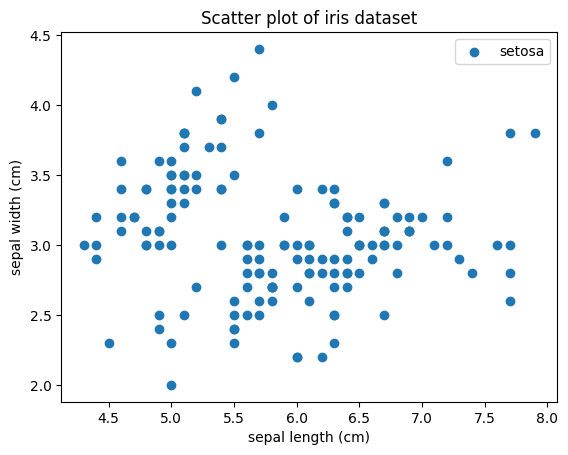

In [21]:
# Scatter plot
plt.scatter(iris_df["sepal length (cm)"], iris_df["sepal width (cm)"])
plt.legend(target_names)
plt.title("Scatter plot of iris dataset")
plt.xlabel("sepal length (cm)")
plt.ylabel("sepal width (cm)")

In [23]:
import seaborn as sns

<Axes: xlabel='sepal length (cm)', ylabel='sepal width (cm)'>

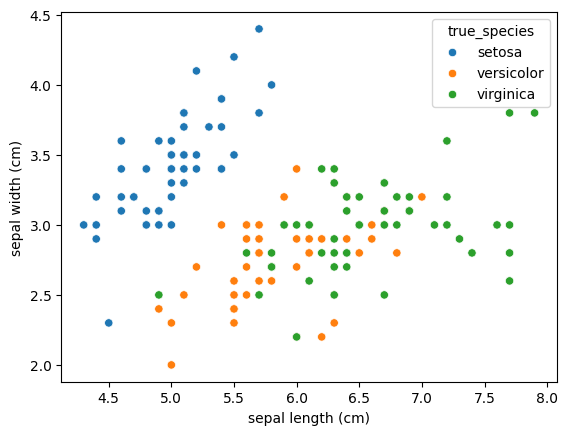

In [24]:
sns.scatterplot(data=iris_df, x="sepal length (cm)", y="sepal width (cm)", hue="true_species")

<Axes: xlabel='petal length (cm)', ylabel='petal width (cm)'>

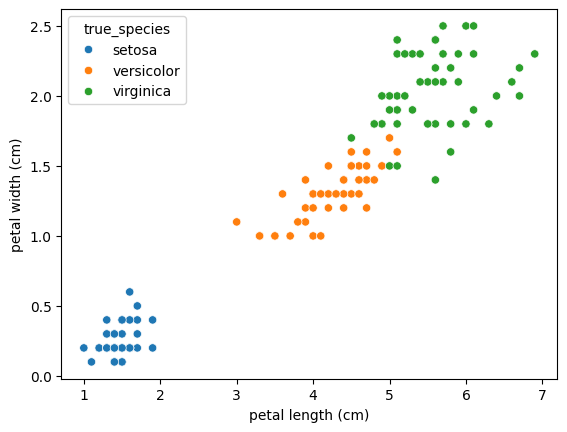

In [28]:
sns.scatterplot(data=iris_df, x="petal length (cm)", y="petal width (cm)", hue="true_species")

## Agglomerative Clustering

In [14]:
number_of_clusters = 3
linkage_used = "complete"

model_full = AgglomerativeClustering(
    n_clusters=number_of_clusters,
    linkage=linkage_used)

labels_full = model_full.fit_predict(X_full)

print("First 150 cluster labels:")
print(labels_full[:150])

print("\nUnique cluster IDs:")
print(np.unique(labels_full))



First 150 cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 2 0 2 0 2 0 2 2 2 2 0 2 0 2 2 0 2 0 2 0 0
 0 0 0 0 0 2 2 2 2 0 2 0 0 0 2 2 2 0 2 2 2 2 2 0 2 2 0 0 0 0 0 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]

Unique cluster IDs:
[0 1 2]


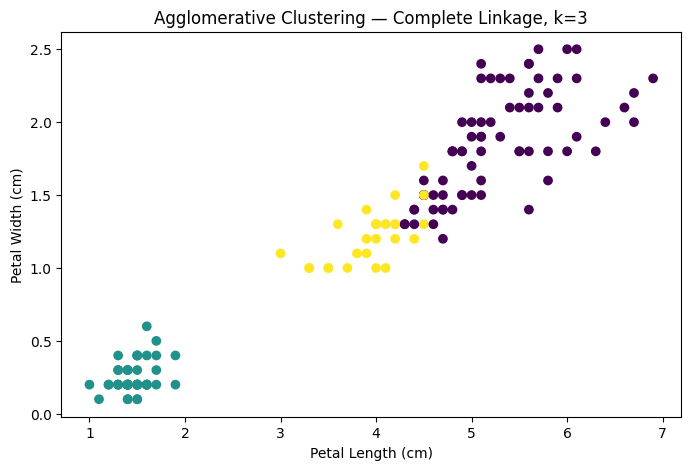

In [36]:
plt.figure(figsize=(8, 5))
plt.scatter(
    X_petal[:, 0],
    X_petal[:, 1],
    c=labels_full
)

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Agglomerative Clustering — Complete Linkage, k=3")
plt.show()

In [29]:
# Silhouette Score
sil_full = metrics.silhouette_score(X_full, labels_full)
print(f"Silhouette score using all 4 features: {sil_full:.4f}")

Silhouette score using all 4 features: 0.5136


## Using two features

In [30]:
X_petal = X_full[:, 2:4]

print("Original shape:", X_full.shape)
print("Petal-only shape:", X_petal.shape)
print("\nFirst five petal observations:")
print(X_petal[:5])

Original shape: (150, 4)
Petal-only shape: (150, 2)

First five petal observations:
[[1.4 0.2]
 [1.4 0.2]
 [1.3 0.2]
 [1.5 0.2]
 [1.4 0.2]]


In [32]:
number_of_clusters = 3
linkage_used = "complete"

model_petal = AgglomerativeClustering(
    n_clusters=number_of_clusters,
    linkage=linkage_used)

labels_petal = model_petal.fit_predict(X_petal)

print("First 150 cluster labels:")
print(labels_petal[:150])

print("\nUnique cluster IDs:")
print(np.unique(labels_petal))


First 150 cluster labels:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 1
 1 1 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 1 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]

Unique cluster IDs:
[0 1 2]


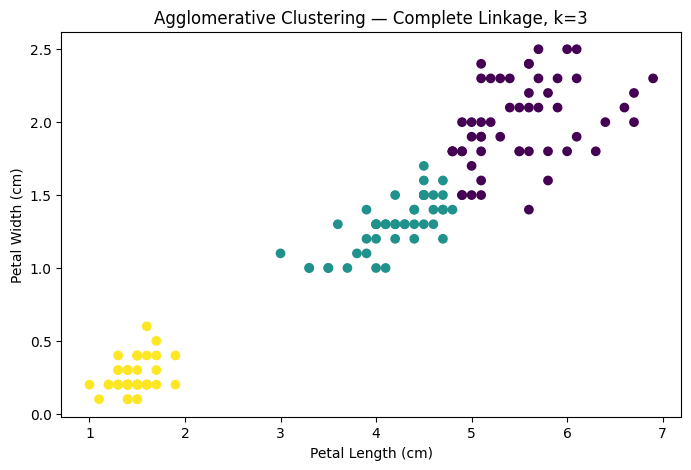

In [33]:
plt.figure(figsize=(8, 5))
plt.scatter(
    X_petal[:, 0],
    X_petal[:, 1],
    c=labels_petal
)

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Agglomerative Clustering — Complete Linkage, k=3")
plt.show()

In [35]:
# Silhouette Score
sil_petal = metrics.silhouette_score(X_petal, labels_petal)
print(f"Silhouette score using petal features: {sil_petal:.4f}")

Silhouette score using petal features: 0.6574


# Build Dandrogram

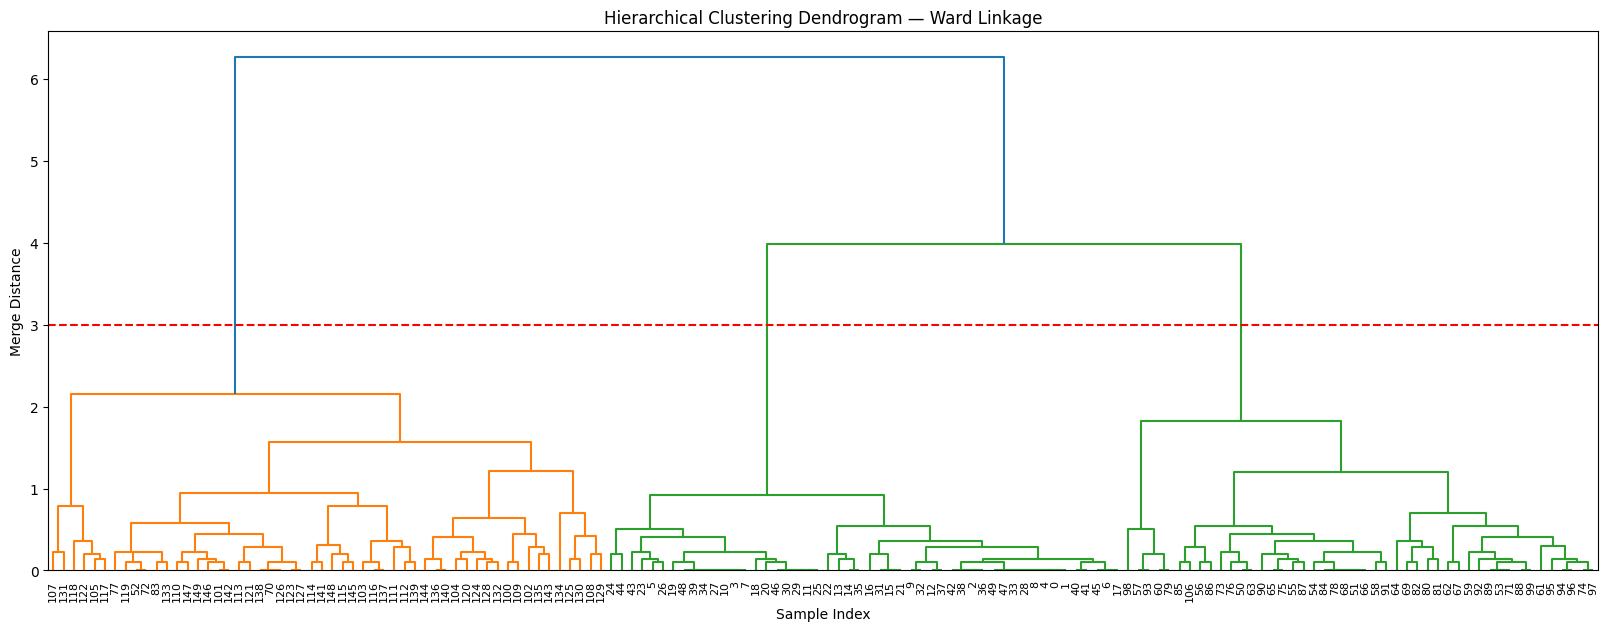

In [42]:
Z = sch.linkage(
    X_petal,
    method="complete",
    metric="euclidean"
    )

plt.figure(figsize=(20, 7))
sch.dendrogram(
    Z,
    leaf_rotation=90,
    leaf_font_size=8)

plt.title("Hierarchical Clustering Dendrogram — Ward Linkage")
plt.xlabel("Sample Index")
plt.ylabel("Merge Distance")
plt.axhline(y=3, linestyle='--', c='r')
plt.show()

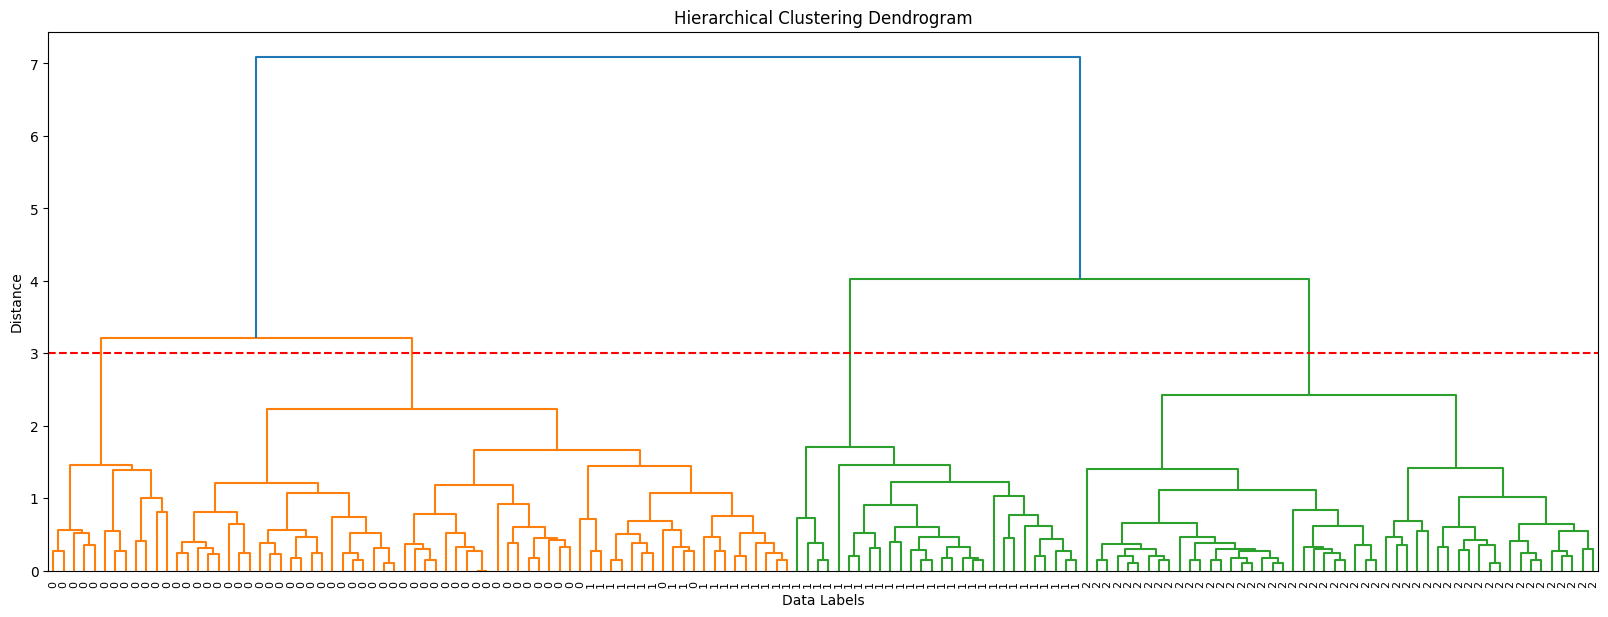

In [46]:
# Plot the dendrogram
plt.figure(figsize=(20, 7))
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Data Labels')
plt.ylabel('Distance')
dendro = sch.dendrogram(sch.linkage(X,linkage_used, metric="euclidean"),
                        labels=labels_petal,
                        leaf_rotation=90,
                        leaf_font_size=8,
                        show_contracted=True)

plt.axhline(y=3, linestyle='--', c='r')
plt.show()

## Linkage Selection

In [47]:
linkages = ["ward", "complete", "average", "single"]
linkage_results = []

for linkage in linkages:
    if linkage == "ward":
        model = AgglomerativeClustering(
            n_clusters=3,
            linkage=linkage
        )
    else:
        model = AgglomerativeClustering(
            n_clusters=3,
            linkage=linkage,
            metric="euclidean"
        )

    labels = model.fit_predict(X_petal)
    score = metrics.silhouette_score(X_petal, labels)

    linkage_results.append({
        "Linkage": linkage,
        "Silhouette Score": score
    })

linkage_results_df = pd.DataFrame(linkage_results)
linkage_results_df.sort_values("Silhouette Score", ascending=False)


,Linkage,Silhouette Score
0,ward,0.657395
1,complete,0.657395
2,average,0.657395
3,single,0.534682


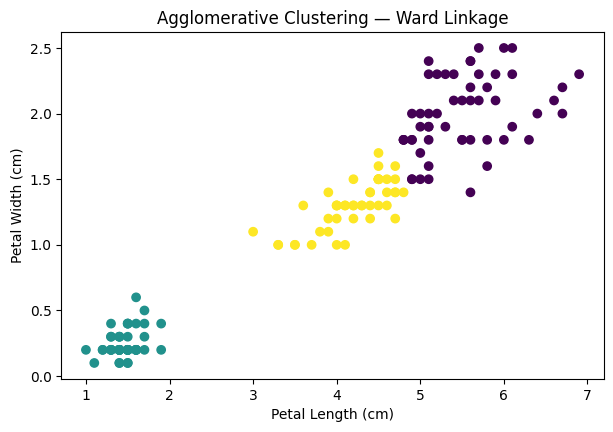

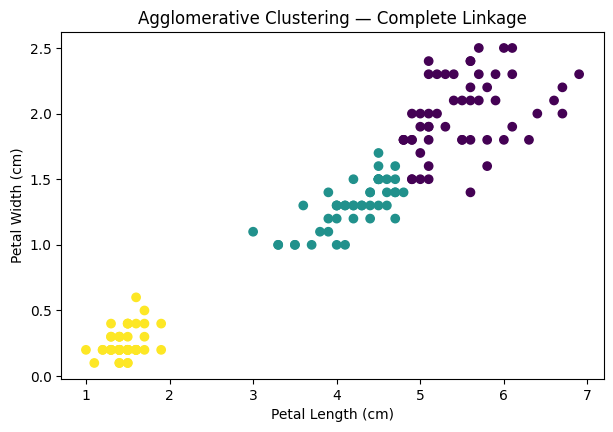

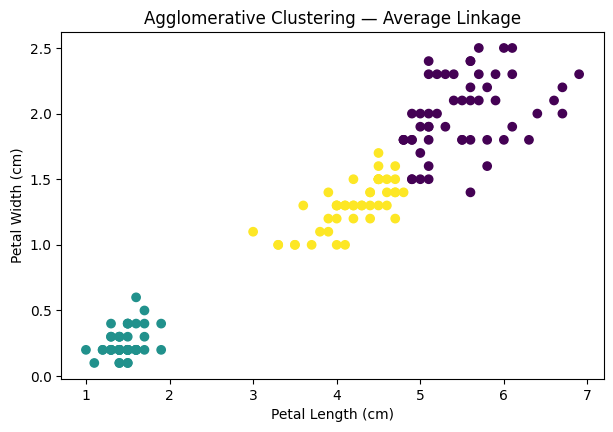

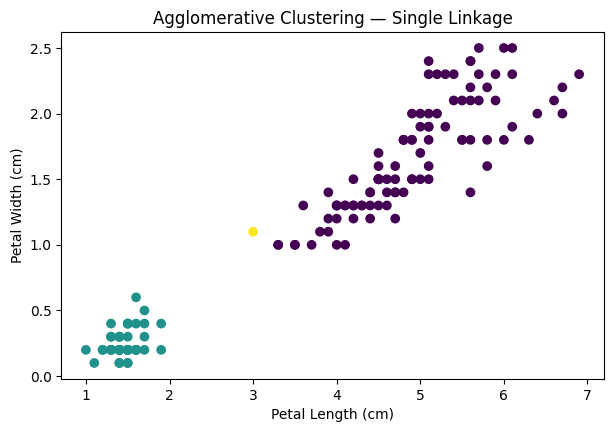

In [48]:
for linkage in linkages:
    if linkage == "ward":
        model = AgglomerativeClustering(
            n_clusters=3,
            linkage=linkage
        )
    else:
        model = AgglomerativeClustering(
            n_clusters=3,
            linkage=linkage,
            metric="euclidean"
        )

    labels = model.fit_predict(X_petal)

    plt.figure(figsize=(7, 4.5))
    plt.scatter(X_petal[:, 0], X_petal[:, 1], c=labels)
    plt.xlabel("Petal Length (cm)")
    plt.ylabel("Petal Width (cm)")
    plt.title(f"Agglomerative Clustering — {linkage.title()} Linkage")
    plt.show()

## Number of clusters

In [49]:
k_results = []

for k in range(2, 7):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_petal)
    score = metrics.silhouette_score(X_petal, labels)

    k_results.append({
        "Number of Clusters (k)": k,
        "Silhouette Score": score
    })

k_results_df = pd.DataFrame(k_results)
k_results_df

,Number of Clusters (k),Silhouette Score
0,2,0.766947
1,3,0.657395
2,4,0.589528
3,5,0.578192
4,6,0.574738


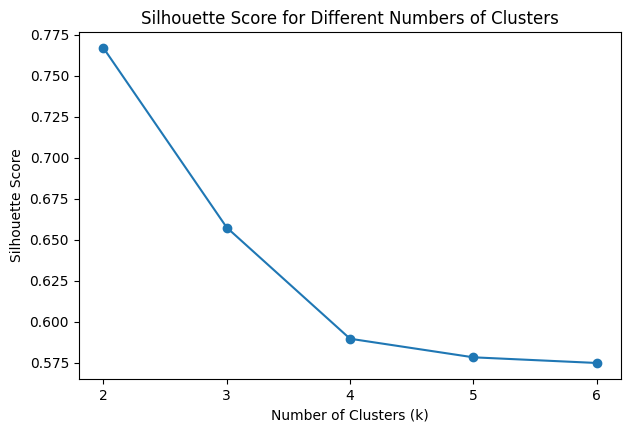

In [50]:
plt.figure(figsize=(7, 4.5))
plt.plot(
    k_results_df["Number of Clusters (k)"],
    k_results_df["Silhouette Score"],
    marker="o"
)
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different Numbers of Clusters")
plt.xticks(k_results_df["Number of Clusters (k)"])
plt.show()

In [51]:
linkages = ["ward", "complete", "average", "single"]
linkage_results = []

for linkage in linkages:
    if linkage == "ward":
        model = AgglomerativeClustering(
            n_clusters=2,
            linkage=linkage
        )
    else:
        model = AgglomerativeClustering(
            n_clusters=2,
            linkage=linkage,
            metric="euclidean"
        )

    labels = model.fit_predict(X_petal)
    score = metrics.silhouette_score(X_petal, labels)

    linkage_results.append({
        "Linkage": linkage,
        "Silhouette Score": score
    })

linkage_results_df = pd.DataFrame(linkage_results)
linkage_results_df.sort_values("Silhouette Score", ascending=False)


,Linkage,Silhouette Score
0,ward,0.766947
2,average,0.766947
3,single,0.766947
1,complete,0.441130


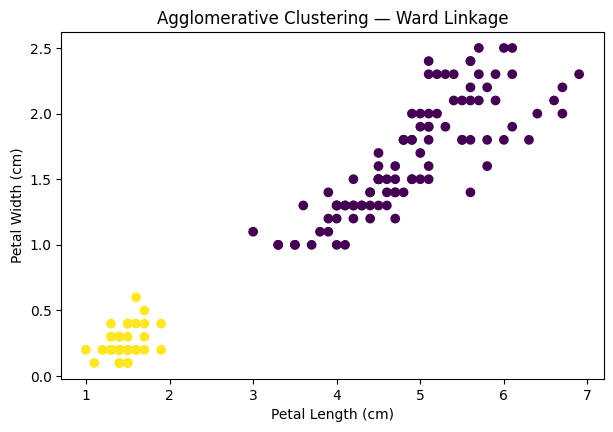

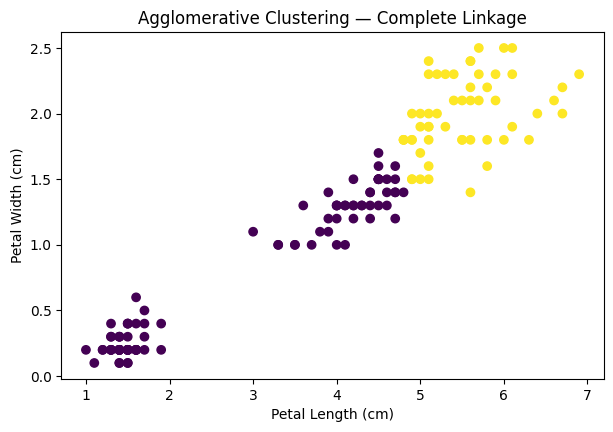

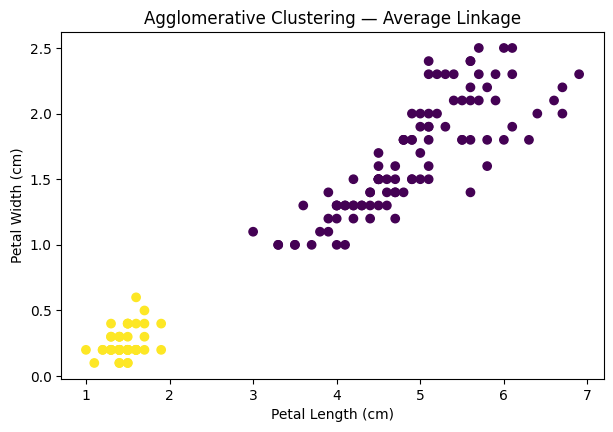

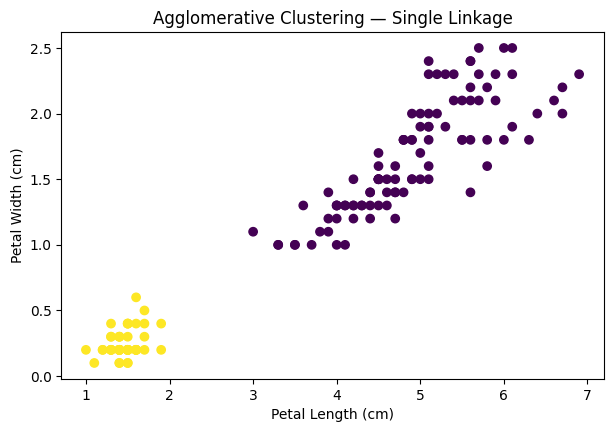

In [52]:
for linkage in linkages:
    if linkage == "ward":
        model = AgglomerativeClustering(
            n_clusters=2,
            linkage=linkage
        )
    else:
        model = AgglomerativeClustering(
            n_clusters=2,
            linkage=linkage,
            metric="euclidean"
        )

    labels = model.fit_predict(X_petal)

    plt.figure(figsize=(7, 4.5))
    plt.scatter(X_petal[:, 0], X_petal[:, 1], c=labels)
    plt.xlabel("Petal Length (cm)")
    plt.ylabel("Petal Width (cm)")
    plt.title(f"Agglomerative Clustering — {linkage.title()} Linkage")
    plt.show()